<a href="https://colab.research.google.com/github/wtraquinas/lab-langchain-evaluation/blob/main/lab_langchain_REMADE_eval_RAG.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Evaluating Machine Translation with LLM-as-a-Judge

(Remade for Colab, after 2 hours in dependencies Hell btwn langchain, torch and transformers)

## Objective

The goal of this notebook is to evaluate the performance of Facebook's
`facebook/nllb-200-distilled-600M` multilingual translation model.

Unlike traditional evaluations that rely only on automatic metrics such as BLEU,
this notebook combines classical MT metrics with an LLM-as-a-Judge approach using
GPT-4.1-mini.

## Pipeline

Dataset

↓

NLLB Translation

 ↓

Automatic Metrics

(BLEU, chrF, TER, BERTScore)
       
   ↓

LLM-as-a-Judge

↓

Analysis & Report



---



## 1 - Dependencies

In [1]:
# ==========================================
# Install dependencies
# ==========================================

!pip -q install \
transformers \
torch \
accelerate \
sentencepiece \
datasets \
evaluate \
bert-score \
sacrebleu \
pandas \
matplotlib \
tqdm \
openai

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 84.1/84.1 kB 9.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 61.1/61.1 kB 7.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 100.8/100.8 kB 12.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 65.9/65.9 kB 8.0 MB/s eta 0:00:00


## 2 - Imports

In [2]:
import time
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from tqdm.auto import tqdm

import torch

from datasets import load_dataset

from transformers import (
    AutoTokenizer,
    AutoModelForSeq2SeqLM
)

import evaluate

## 3 — Configuration

In [3]:
# ==========================================
# Configuration
# ==========================================

MODEL_NAME = "facebook/nllb-200-distilled-600M"

SOURCE_LANG = "eng_Latn"

TARGET_LANG = "por_Latn"

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"

BATCH_SIZE = 16

MAX_LENGTH = 128

SEED = 42

## 4 — Reproducibility

In [4]:
random.seed(SEED)

np.random.seed(SEED)

torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

## 5 — GPU Detection

In [5]:
print("="*50)

print(f"Device: {DEVICE}")

if DEVICE=="cuda":
    print(torch.cuda.get_device_name(0))

print("="*50)

Device: cuda
NVIDIA L4


## 6 — Load NLLB

In [6]:
print("Loading tokenizer...")

tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

print("Loading model...")

model = AutoModelForSeq2SeqLM.from_pretrained(
    MODEL_NAME
).to(DEVICE)

print("Done!")

Loading tokenizer...


config.json:   0%|          | 0.00/846 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/564 [00:00<?, ?B/s]

sentencepiece.bpe.model: reconstructing file:   0%|          |  0.00B / 4.85MB            

sentencepiece.bpe.model: downloading bytes:           |  0.00B            

tokenizer.json: reconstructing file:   0%|          |  0.00B / 17.3MB            

... (6 outputs left out)

generation_config.json:   0%|          | 0.00/189 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 2.46GB            

model.safetensors: downloading bytes:           |  0.00B            

Done!


## 7 — First Translation

In [7]:
def translate(text):

    tokenizer.src_lang = SOURCE_LANG

    encoded = tokenizer(
        text,
        return_tensors="pt",
        truncation=True
    ).to(DEVICE)

    generated = model.generate(
        **encoded,
        forced_bos_token_id=tokenizer.convert_tokens_to_ids(TARGET_LANG),
        max_length=MAX_LENGTH
    )

    return tokenizer.batch_decode(
        generated,
        skip_special_tokens=True
    )[0]

### Testing

In [8]:
sentence = "Artificial Intelligence is transforming healthcare."

translation = translate(sentence)

print(sentence)

print()

print(translation)

Artificial Intelligence is transforming healthcare.

A Inteligência Artificial está a transformar a saúde.


### evaluation dataset

In [10]:
import pandas as pd

df = pd.DataFrame({
    "source": [
        "Artificial Intelligence is transforming healthcare.",
        "The weather is beautiful today.",
        "Machine learning is a subset of artificial intelligence.",
        "The meeting starts at nine o'clock.",
        "I enjoy learning new programming languages."
    ],
    "reference": [
        "A Inteligência Artificial está a transformar os cuidados de saúde.",
        "O tempo está bonito hoje.",
        "A aprendizagem automática é um subconjunto da inteligência artificial.",
        "A reunião começa às nove horas.",
        "Gosto de aprender novas linguagens de programação."
    ]
})

df.head()

,source,reference
0,Artificial Intelligence is transforming health...,A Inteligência Artificial está a transformar o...
1,The weather is beautiful today.,O tempo está bonito hoje.
2,Machine learning is a subset of artificial int...,A aprendizagem automática é um subconjunto da ...
3,The meeting starts at nine o'clock.,A reunião começa às nove horas.
4,I enjoy learning new programming languages.,Gosto de aprender novas linguagens de programa...


In [11]:
predictions = []

for text in tqdm(df["source"]):
    predictions.append(translate(text))

df["prediction"] = predictions

df.head()

  0%|          | 0/5 [00:00<?, ?it/s]

,source,reference,prediction
0,Artificial Intelligence is transforming health...,A Inteligência Artificial está a transformar o...,A Inteligência Artificial está a transformar a...
1,The weather is beautiful today.,O tempo está bonito hoje.,O tempo é lindo hoje.
2,Machine learning is a subset of artificial int...,A aprendizagem automática é um subconjunto da ...,O aprendizado de máquina é um subconjunto de i...
3,The meeting starts at nine o'clock.,A reunião começa às nove horas.,A reunião começa às nove.
4,I enjoy learning new programming languages.,Gosto de aprender novas linguagens de programa...,Gosto de aprender novas linguagens de programa...


## 8 — Batch Translation

In [12]:
predictions = []

for text in tqdm(df["source"]):
    predictions.append(translate(text))

  0%|          | 0/5 [00:00<?, ?it/s]



---



### Create sample_dataset.csv

In [15]:
import pandas as pd

df = pd.DataFrame({
    "source": [
        "Artificial Intelligence is transforming healthcare.",
        "Machine learning models require high-quality data.",
        "Natural language processing enables computers to understand text.",
        "The weather is beautiful today.",
        "The meeting starts at nine o'clock.",
        "OpenAI develops advanced AI models.",
        "I enjoy reading books during the weekend.",
        "The train arrived twenty minutes late.",
        "She speaks three different languages.",
        "Technology is changing the world rapidly."
    ],
    "reference": [
        "A Inteligência Artificial está a transformar os cuidados de saúde.",
        "Os modelos de aprendizagem automática requerem dados de elevada qualidade.",
        "O processamento de linguagem natural permite aos computadores compreender texto.",
        "O tempo está bonito hoje.",
        "A reunião começa às nove horas.",
        "A OpenAI desenvolve modelos avançados de IA.",
        "Gosto de ler livros durante o fim de semana.",
        "O comboio chegou com vinte minutos de atraso.",
        "Ela fala três línguas diferentes.",
        "A tecnologia está a mudar o mundo rapidamente."
    ]
})

df.to_csv("sample_dataset.csv", index=False)

df.head()

,source,reference
0,Artificial Intelligence is transforming health...,A Inteligência Artificial está a transformar o...
1,Machine learning models require high-quality d...,Os modelos de aprendizagem automática requerem...
2,Natural language processing enables computers ...,O processamento de linguagem natural permite a...
3,The weather is beautiful today.,O tempo está bonito hoje.
4,The meeting starts at nine o'clock.,A reunião começa às nove horas.


### Read Dataset

In [16]:
import pandas as pd

df = pd.read_csv("sample_dataset.csv")

df.head()

,source,reference
0,Artificial Intelligence is transforming health...,A Inteligência Artificial está a transformar o...
1,Machine learning models require high-quality d...,Os modelos de aprendizagem automática requerem...
2,Natural language processing enables computers ...,O processamento de linguagem natural permite a...
3,The weather is beautiful today.,O tempo está bonito hoje.
4,The meeting starts at nine o'clock.,A reunião começa às nove horas.


## Translate

In [17]:
from tqdm.auto import tqdm

predictions = []

for text in tqdm(df["source"]):
    predictions.append(translate(text))

df["prediction"] = predictions

df.head()

  0%|          | 0/10 [00:00<?, ?it/s]

,source,reference,prediction
0,Artificial Intelligence is transforming health...,A Inteligência Artificial está a transformar o...,A Inteligência Artificial está a transformar a...
1,Machine learning models require high-quality d...,Os modelos de aprendizagem automática requerem...,Os modelos de aprendizagem automática exigem d...
2,Natural language processing enables computers ...,O processamento de linguagem natural permite a...,O processamento de linguagem natural permite q...
3,The weather is beautiful today.,O tempo está bonito hoje.,O tempo é lindo hoje.
4,The meeting starts at nine o'clock.,A reunião começa às nove horas.,A reunião começa às nove.


## Save predictions

In [18]:
df.to_csv("predictions.csv", index=False)

## Compute the metrics

### BLEU

In [19]:
import evaluate

bleu = evaluate.load("bleu")

bleu.compute(
    predictions=df["prediction"].tolist(),
    references=[[r] for r in df["reference"]]
)

{'bleu': 0.6239115382909342,
 'precisions': [0.8372093023255814,
  0.6842105263157895,
  0.5606060606060606,
  0.5178571428571429],
 'brevity_penalty': 0.9770125183673897,
 'length_ratio': 0.9772727272727273,
 'translation_length': 86,
 'reference_length': 88}

### chrF

In [20]:
chrf = evaluate.load("chrf")

### TER

In [21]:
ter = evaluate.load("ter")

### BERTScore

In [22]:
bertscore = evaluate.load("bertscore")



---



## Translation Pipeline

In [23]:
from tqdm.auto import tqdm
import time

def translate_dataset(df, text_column="source"):
    """
    Translate all sentences in a DataFrame.

    Args:
        df: pandas DataFrame
        text_column: column containing source text

    Returns:
        DataFrame with prediction column
    """

    predictions = []

    start = time.time()

    for sentence in tqdm(df[text_column]):

        prediction = translate(sentence)

        predictions.append(prediction)

    elapsed = time.time() - start

    df = df.copy()
    df["prediction"] = predictions

    print(f"\nTranslated {len(df)} sentences")
    print(f"Time: {elapsed:.2f} sec")
    print(f"Speed: {len(df)/elapsed:.2f} sentences/sec")

    return df

## Dataset

In [24]:
df = translate_dataset(df)

  0%|          | 0/10 [00:00<?, ?it/s]


Translated 10 sentences
Time: 2.08 sec
Speed: 4.82 sentences/sec


## Save everything

In [25]:
import os

os.makedirs("results", exist_ok=True)

df.to_csv("results/predictions.csv", index=False)

print("Saved results/predictions.csv")

Saved results/predictions.csv


## Evaluation Module

In [26]:
import evaluate

bleu = evaluate.load("bleu")
chrf = evaluate.load("chrf")
ter = evaluate.load("ter")
bertscore = evaluate.load("bertscore")

In [27]:
def evaluate_mt(df):

    predictions = df["prediction"].tolist()

    references = [[r] for r in df["reference"]]

    results = {}

    results["BLEU"] = bleu.compute(
        predictions=predictions,
        references=references
    )["bleu"]

    results["chrF"] = chrf.compute(
        predictions=predictions,
        references=references
    )["score"]

    results["TER"] = ter.compute(
        predictions=predictions,
        references=references
    )["score"]

    bert = bertscore.compute(
        predictions=predictions,
        references=df["reference"].tolist(),
        lang="pt"
    )

    results["BERTScore"] = sum(bert["f1"])/len(bert["f1"])

    return results

## Metrics

In [28]:
metrics = evaluate_mt(df)

metrics

config.json:   0%|          | 0.00/625 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/49.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/996k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.96M [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  714MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: bert-base-multilingual-cased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


{'BLEU': 0.6239115382909342,
 'chrF': 79.69552295697095,
 'TER': 24.358974358974358,
 'BERTScore': 0.9552599132061005}

In [29]:
metrics_df = (
    pd.DataFrame(metrics.items(), columns=["Metric", "Value"])
)

metrics_df

,Metric,Value
0,BLEU,0.623912
1,chrF,79.695523
2,TER,24.358974
3,BERTScore,0.955260


## Normalization of metrics

In [32]:
normalized_metrics = {
    "BLEU": metrics["BLEU"] * 100,
    "chrF": metrics["chrF"],
    "TER": 100 - metrics["TER"],   # invert because lower TER is better
    "BERTScore": metrics["BERTScore"] * 100
}

normalized_metrics

{'BLEU': 62.39115382909341,
 'chrF': 79.69552295697095,
 'TER': 75.64102564102564,
 'BERTScore': 95.52599132061005}

## Normalized Dataframe

In [33]:
metrics_norm = pd.DataFrame({
    "Metric": normalized_metrics.keys(),
    "Score": normalized_metrics.values()
})

metrics_norm

,Metric,Score
0,BLEU,62.391154
1,chrF,79.695523
2,TER,75.641026
3,BERTScore,95.525991


## Radar Chart

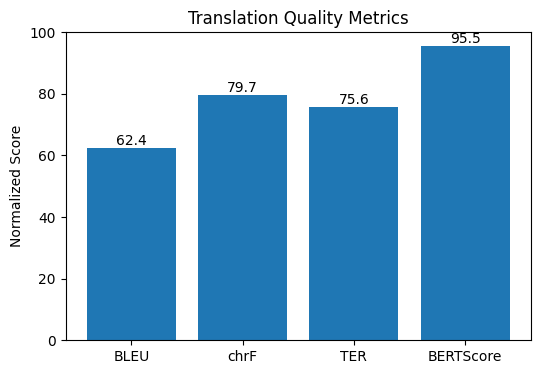

In [34]:
import matplotlib.pyplot as plt

plt.figure(figsize=(6,4))

plt.bar(
    metrics_norm["Metric"],
    metrics_norm["Score"]
)

plt.ylim(0,100)
plt.ylabel("Normalized Score")
plt.title("Translation Quality Metrics")

for i, score in enumerate(metrics_norm["Score"]):
    plt.text(i, score+1, f"{score:.1f}", ha="center")

plt.show()

## Overall Translation Quality Score (TQS)

In [35]:
weights = {
    "BLEU": 0.20,
    "chrF": 0.20,
    "TER": 0.20,
    "BERTScore": 0.40
}

tqs = (
    normalized_metrics["BLEU"] * weights["BLEU"] +
    normalized_metrics["chrF"] * weights["chrF"] +
    normalized_metrics["TER"] * weights["TER"] +
    normalized_metrics["BERTScore"] * weights["BERTScore"]
)

print(f"Translation Quality Score: {tqs:.2f}/100")

Translation Quality Score: 81.76/100


## Save Metrics

In [36]:
metrics_df.to_csv(
    "results/metrics.csv",
    index=False
)



---



# LLM-as-a-Judge

### OPENAI SDK

In [37]:
!pip install -q openai

### API Key

In [41]:
from google.colab import userdata

OPENAI_API_KEY = userdata.get('OPENAI_API_KEY')

### Client

In [43]:
from openai import OpenAI

client = OpenAI(api_key=OPENAI_API_KEY)

### Judge function, returning structured JSON

In [44]:
import json

def judge_translation(source, reference, prediction):

    prompt = f"""
You are an expert evaluator of machine translation.

Evaluate the candidate translation.

Source:
{source}

Reference:
{reference}

Candidate:
{prediction}

Rate from 1 to 5:

- accuracy
- fluency
- meaning_preservation
- grammar
- naturalness
- overall

Return ONLY valid JSON.

Example:

{{
"accuracy":5,
"fluency":4,
"meaning_preservation":5,
"grammar":5,
"naturalness":4,
"overall":5,
"reason":"..."
}}
"""

    response = client.responses.create(
        model="gpt-4.1-mini",
        input=prompt,
        temperature=0
    )

    return json.loads(response.output_text)

### Test on 1 sentence

In [45]:
result = judge_translation(
    df.loc[0, "source"],
    df.loc[0, "reference"],
    df.loc[0, "prediction"]
)

result

{'accuracy': 4,
 'fluency': 5,
 'meaning_preservation': 4,
 'grammar': 5,
 'naturalness': 5,
 'overall': 4,
 'reason': "The candidate translation is fluent, grammatically correct, and natural in Portuguese. However, it slightly reduces the specificity of the original phrase by translating 'healthcare' as 'saúde' (health) instead of 'cuidados de saúde' (healthcare), which may imply a broader or different meaning. Despite this, the core meaning is preserved well."}